In [1]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd().parent

# MVTec dataset
MVTEC_PATH = PROJECT_ROOT / "datasets" / "mvtec_anomaly_detection"

print("Project root:", PROJECT_ROOT)
print("MVTec path:", MVTEC_PATH)
print("MVTec exists:", MVTEC_PATH.exists())

Project root: c:\Users\rimjh\IndustrialDefectProject
MVTec path: c:\Users\rimjh\IndustrialDefectProject\datasets\mvtec_anomaly_detection
MVTec exists: True


In [2]:
# Get all MVTec categories

categories = sorted([
    folder.name
    for folder in MVTEC_PATH.iterdir()
    if folder.is_dir()
])

print("Number of categories:", len(categories))
print("\nCategories:")

for category in categories:
    print("-", category)

Number of categories: 15

Categories:
- bottle
- cable
- capsule
- carpet
- grid
- hazelnut
- leather
- metal_nut
- pill
- screw
- tile
- toothbrush
- transistor
- wood
- zipper


In [3]:
# Count images in train and test for each category

image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}

print("MVTec Image Counts")
print("=" * 50)

for category in categories:
    category_path = MVTEC_PATH / category

    train_images = list((category_path / "train").rglob("*"))
    test_images = list((category_path / "test").rglob("*"))

    train_images = [
        f for f in train_images
        if f.is_file() and f.suffix.lower() in image_extensions
    ]

    test_images = [
        f for f in test_images
        if f.is_file() and f.suffix.lower() in image_extensions
    ]

    print(
        f"{category:12} | "
        f"Train: {len(train_images):4} | "
        f"Test: {len(test_images):4}"
    )

MVTec Image Counts
bottle       | Train:  209 | Test:   83
cable        | Train:  224 | Test:  150
capsule      | Train:  219 | Test:  132
carpet       | Train:  280 | Test:  117
grid         | Train:  264 | Test:   78
hazelnut     | Train:  391 | Test:  110
leather      | Train:  245 | Test:  124
metal_nut    | Train:  220 | Test:  115
pill         | Train:  267 | Test:  167
screw        | Train:  320 | Test:  160
tile         | Train:  230 | Test:  117
toothbrush   | Train:   60 | Test:   42
transistor   | Train:  213 | Test:  100
wood         | Train:  247 | Test:   79
zipper       | Train:  240 | Test:  151


In [4]:
# Count normal and defective test images

print("MVTec Test Image Breakdown")
print("=" * 65)

for category in categories:
    test_path = MVTEC_PATH / category / "test"

    normal_count = 0
    defective_count = 0

    for defect_type in test_path.iterdir():
        if not defect_type.is_dir():
            continue

        images = [
            f for f in defect_type.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        ]

        if defect_type.name == "good":
            normal_count += len(images)
        else:
            defective_count += len(images)

    print(
        f"{category:12} | "
        f"Normal: {normal_count:3} | "
        f"Defective: {defective_count:3} | "
        f"Total: {normal_count + defective_count:3}"
    )

MVTec Test Image Breakdown
bottle       | Normal:  20 | Defective:  63 | Total:  83
cable        | Normal:  58 | Defective:  92 | Total: 150
capsule      | Normal:  23 | Defective: 109 | Total: 132
carpet       | Normal:  28 | Defective:  89 | Total: 117
grid         | Normal:  21 | Defective:  57 | Total:  78
hazelnut     | Normal:  40 | Defective:  70 | Total: 110
leather      | Normal:  32 | Defective:  92 | Total: 124
metal_nut    | Normal:  22 | Defective:  93 | Total: 115
pill         | Normal:  26 | Defective: 141 | Total: 167
screw        | Normal:  41 | Defective: 119 | Total: 160
tile         | Normal:  33 | Defective:  84 | Total: 117
toothbrush   | Normal:  12 | Defective:  30 | Total:  42
transistor   | Normal:  60 | Defective:  40 | Total: 100
wood         | Normal:  19 | Defective:  60 | Total:  79
zipper       | Normal:  32 | Defective: 119 | Total: 151


In [5]:
# List defect types for each MVTec category

print("MVTec Defect Types")
print("=" * 65)

for category in categories:
    test_path = MVTEC_PATH / category / "test"

    defect_types = sorted([
        folder.name
        for folder in test_path.iterdir()
        if folder.is_dir() and folder.name != "good"
    ])

    print(f"\n{category}:")
    for defect in defect_types:
        print(f"  - {defect}")

MVTec Defect Types

bottle:
  - broken_large
  - broken_small
  - contamination

cable:
  - bent_wire
  - cable_swap
  - combined
  - cut_inner_insulation
  - cut_outer_insulation
  - missing_cable
  - missing_wire
  - poke_insulation

capsule:
  - crack
  - faulty_imprint
  - poke
  - scratch
  - squeeze

carpet:
  - color
  - cut
  - hole
  - metal_contamination
  - thread

grid:
  - bent
  - broken
  - glue
  - metal_contamination
  - thread

hazelnut:
  - crack
  - cut
  - hole
  - print

leather:
  - color
  - cut
  - fold
  - glue
  - poke

metal_nut:
  - bent
  - color
  - flip
  - scratch

pill:
  - color
  - combined
  - contamination
  - crack
  - faulty_imprint
  - pill_type
  - scratch

screw:
  - manipulated_front
  - scratch_head
  - scratch_neck
  - thread_side
  - thread_top

tile:
  - crack
  - glue_strip
  - gray_stroke
  - oil
  - rough

toothbrush:
  - defective

transistor:
  - bent_lead
  - cut_lead
  - damaged_case
  - misplaced

wood:
  - color
  - combined
  - 

Normal image: c:\Users\rimjh\IndustrialDefectProject\datasets\mvtec_anomaly_detection\bottle\test\good\000.png
Defective image: c:\Users\rimjh\IndustrialDefectProject\datasets\mvtec_anomaly_detection\bottle\test\broken_large\000.png


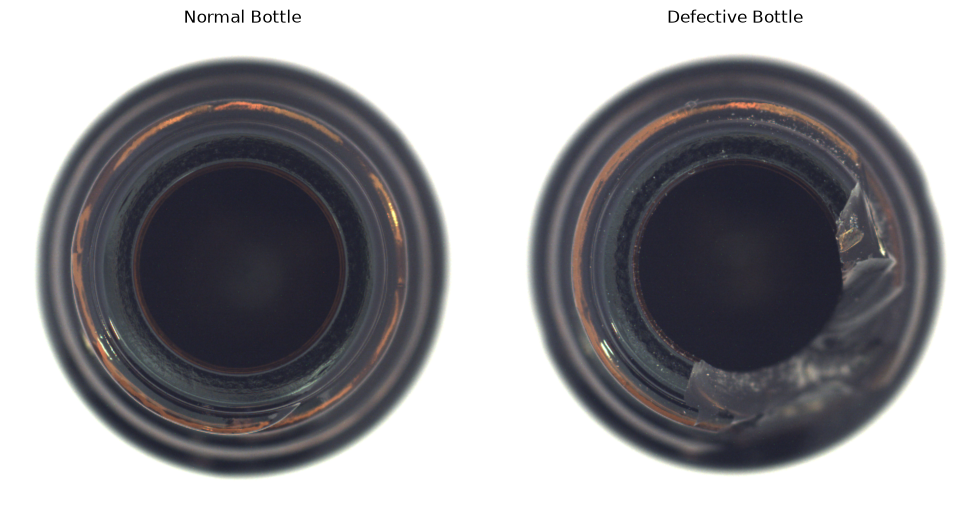

In [6]:
from PIL import Image
import matplotlib.pyplot as plt

# Select one normal image
normal_images = list(
    (MVTEC_PATH / "bottle" / "test" / "good").glob("*")
)

# Select one defective image
defect_images = list(
    (MVTEC_PATH / "bottle" / "test" / "broken_large").glob("*")
)

print("Normal image:", normal_images[0])
print("Defective image:", defect_images[0])

# Display both
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(Image.open(normal_images[0]))
axes[0].set_title("Normal Bottle")
axes[0].axis("off")

axes[1].imshow(Image.open(defect_images[0]))
axes[1].set_title("Defective Bottle")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Mask path: c:\Users\rimjh\IndustrialDefectProject\datasets\mvtec_anomaly_detection\bottle\ground_truth\broken_large\000_mask.png
Mask exists: True


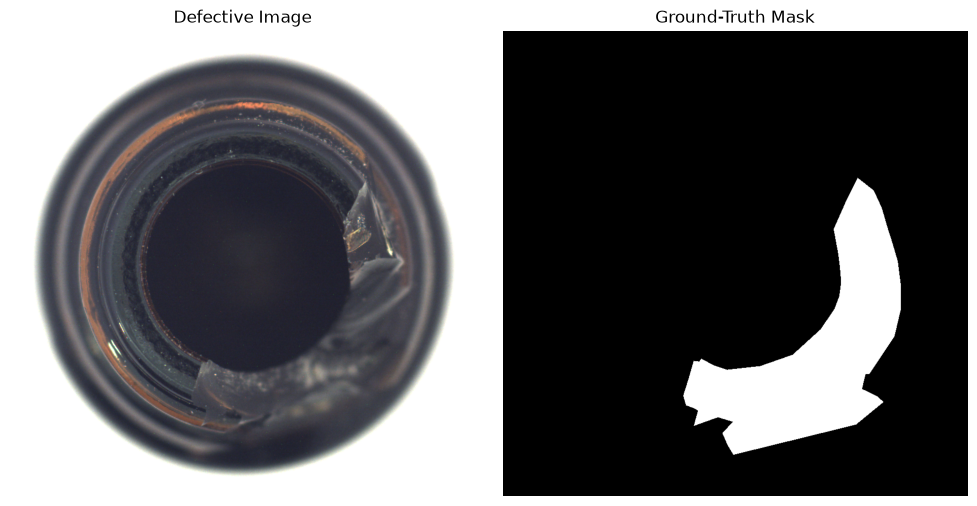

In [7]:
# Load the ground-truth mask for the defective image

defect_image = defect_images[0]

# The corresponding mask has the same filename
mask_path = (
    MVTEC_PATH
    / "bottle"
    / "ground_truth"
    / "broken_large"
    / defect_image.name.replace(".png", "_mask.png")
)

print("Mask path:", mask_path)
print("Mask exists:", mask_path.exists())

# Display defective image and its mask
defect_img = Image.open(defect_image)
mask_img = Image.open(mask_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(defect_img)
axes[0].set_title("Defective Image")
axes[0].axis("off")

axes[1].imshow(mask_img, cmap="gray")
axes[1].set_title("Ground-Truth Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

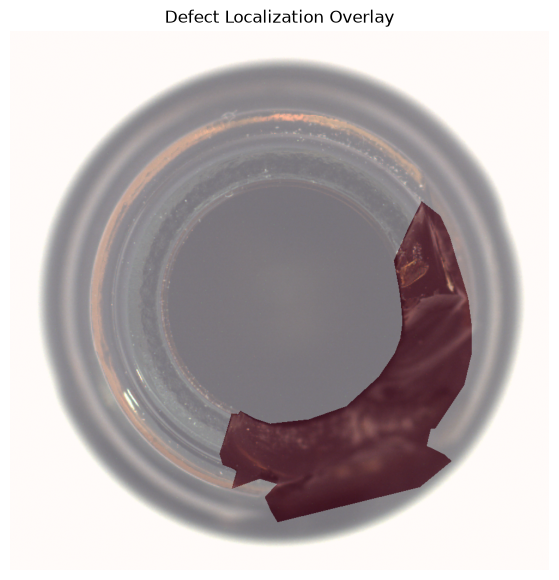

In [8]:
# Create an overlay of the defect mask on the defective image

import numpy as np

# Convert images to arrays
image_array = np.array(defect_img)
mask_array = np.array(mask_img)

# Create a figure
plt.figure(figsize=(7, 7))

plt.imshow(image_array)
plt.imshow(mask_array, cmap="Reds", alpha=0.4)

plt.title("Defect Localization Overlay")
plt.axis("off")

plt.show()